# Klike Challenge — Part 1: Data Treatment and Exploratory Analysis

This notebook covers **Part 1**: understanding the dataset, cleaning it, and exploring what
drives creative performance.

The order matters. The dataset arrived **damaged in a specific, reversible way**, and the
obvious way to clean it — drop whatever will not parse — would destroy precisely the most
informative part of the data. So the notebook runs in this order:

1. **Diagnosis** — what exactly is wrong, and why
2. **Treatment** — recover rather than discard, validating each step
3. **EDA** — what moves the Klike Score, CTR, ROAS and conversions
4. **Platform patterns** — does what works on TikTok work on LinkedIn?
5. **Visualisations** for a marketing team

Everything is self-contained: all it needs is the `.xlsx` in this folder (or in `data/`).

In [1]:
import datetime as dt
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import openpyxl
import pandas as pd
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

# Look for the dataset in the most likely places.
CANDIDATES = [
    Path("klike_challenge_dataset.xlsx"),
    Path("data/klike_challenge_dataset.xlsx"),
    Path("data/raw/klike_challenge_dataset.xlsx"),
    Path("../data/klike_challenge_dataset.xlsx"),
]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Put klike_challenge_dataset.xlsx in this folder or in data/. "
        f"Looked in: {[str(p) for p in CANDIDATES]}"
    )
print(f"dataset: {DATA_PATH}")

dataset: klike_challenge_dataset.xlsx


---

# 1. Diagnosis: what is wrong with the data

## 1.1 First look

In [2]:
raw = pd.read_excel(DATA_PATH)
print(f"{raw.shape[0]} rows x {raw.shape[1]} columns\n")
print(raw.dtypes.to_string())

500 rows x 26 columns

campaign_id                       str
date                   datetime64[us]
platform                          str
category                          str
objective                         str
target_audience_age               str
is_retargeting                   bool
video_duration_s              float64
format                            str
has_subtitle                  float64
has_cta                          bool
has_hook                         bool
has_face                         bool
text_density                      str
music_voice_ratio             float64
impressions                     int64
clicks                          int64
ctr                           float64
cpc                            object
spend                          object
conversions                     int64
revenue                        object
roas                           object
avg_watch_time_s               object
engagement_rate               float64
klike_score                

Six columns that should be numeric came back as `object`: `cpc`, `spend`, `revenue`, `roas`,
`avg_watch_time_s` and `klike_score` — **including the target**. Let us look inside them.

In [3]:
SUSPECT = ["cpc", "spend", "revenue", "roas", "avg_watch_time_s", "klike_score"]
pd.DataFrame({
    col: raw[col].map(lambda v: type(v).__name__).value_counts()
    for col in SUSPECT
}).fillna(0).astype(int)

,cpc,spend,revenue,roas,avg_watch_time_s,klike_score
datetime,41,54,21,51,375,16
float,28,0,25,0,27,0
str,431,446,454,449,98,484


In [4]:
# Dates inside a money column? Let's see some examples.
for col in ["avg_watch_time_s", "spend", "klike_score"]:
    dates = raw[col][raw[col].map(lambda v: isinstance(v, dt.datetime))]
    print(f"{col:18s} {len(dates):3d} dates | e.g. {[str(v.date()) for v in dates[:4]]}")

avg_watch_time_s   375 dates | e.g. ['2026-09-03', '2026-04-06', '2026-03-20', '2026-02-08']
spend               54 dates | e.g. ['2223-02-01', '1915-03-01', '2278-08-01', '5353-04-01']
klike_score         16 dates | e.g. ['2026-07-23', '2026-04-10', '2026-06-26', '2026-03-27']


## 1.2 Root cause: Excel's date autoconversion

`spend` holding values in **1915** and **2223**, `avg_watch_time_s` holding dates in 2026.
This is not random noise — it is a classic spreadsheet bug.

When someone types `3.9` into a General-formatted cell, Excel reads it as **3 September**,
stores the serial number `46268`, and attaches the display format `d.m`. On screen the cell
**still reads "3.9"**. Whoever opens the file sees nothing wrong; only `pandas` sees a date.

And the display format is exactly what makes it reversible: re-rendering the serial through
the cell's own format code returns the original digits. That requires reading the file cell
by cell with `openpyxl` — `pandas` throws the formatting away.

In [5]:
# Which display formats exist in this file?
sheet = openpyxl.load_workbook(DATA_PATH).active

formats = {}
for row in sheet.iter_rows(min_row=2):
    for cell in row:
        if isinstance(cell.value, dt.datetime):
            formats[cell.number_format] = formats.get(cell.number_format, 0) + 1

pd.Series(formats).rename("cells").sort_values(ascending=False).to_frame()

,cells
yyyy-mm-dd,500
d.m,434
yyyy.m,53
dd.mm,52
yyyy.mm,19


`yyyy-mm-dd` is the genuine `date` column — that one stays as it is. The other four formats
are the bug's signature, and each one says exactly how the digits were split:

| format | stored serial | original value |
|---|---|---|
| `d.m` | 2026-09-03 | `3.9` |
| `dd.mm` | 2026-09-03 | `3.09` |
| `yyyy.m` | 2223-02-01 | `2223.2` |
| `yyyy.mm` | 1915-03-01 | `1915.03` |

In [6]:
CORRUPTION_FORMATS = {
    "d.m":     lambda d: f"{d.day}.{d.month}",
    "dd.mm":   lambda d: f"{d.day:02d}.{d.month:02d}",
    "yyyy.m":  lambda d: f"{d.year}.{d.month}",
    "yyyy.mm": lambda d: f"{d.year}.{d.month:02d}",
}


def load_with_recovery(path):
    """Read the workbook cell by cell, undoing Excel's date autoconversion.

    Returns (dataframe, boolean mask of recovered cells, count per format).
    """
    sheet = openpyxl.load_workbook(path, data_only=True).active
    header = [c.value for c in sheet[1]]

    records, recovered_flags, per_format = [], [], {}
    for row in sheet.iter_rows(min_row=2):
        record, marks = {}, {}
        for column, cell in zip(header, row):
            value, marks[column] = cell.value, False
            if isinstance(value, dt.datetime):
                render = CORRUPTION_FORMATS.get(cell.number_format)
                if render is not None:
                    value = float(render(value))
                    marks[column] = True
                    key = (column, cell.number_format)
                    per_format[key] = per_format.get(key, 0) + 1
            record[column] = value
        records.append(record)
        recovered_flags.append(marks)

    frame = pd.DataFrame(records, columns=header)
    mask = pd.DataFrame(recovered_flags, columns=header).astype(bool)
    return frame, mask, per_format


df, recovered, per_format = load_with_recovery(DATA_PATH)
print(f"{int(recovered.to_numpy().sum())} cells recovered\n")

summary = (
    pd.Series(per_format).rename("cells")
    .rename_axis(["column", "format"]).reset_index()
    .pivot(index="column", columns="format", values="cells")
    .fillna(0).astype(int)
)
summary["total"] = summary.sum(axis=1)
summary["% of column"] = (summary["total"] / len(df) * 100).round(0).astype(int).astype(str) + "%"
summary.sort_values("total", ascending=False)

558 cells recovered



format,d.m,dd.mm,yyyy.m,yyyy.mm,total,% of column
column,,,,,,
avg_watch_time_s,375,0,0,0,375,75%
spend,2,0,40,12,54,11%
roas,30,21,0,0,51,10%
cpc,11,30,0,0,41,8%
revenue,0,1,13,7,21,4%
klike_score,16,0,0,0,16,3%


## 1.3 Why dropping these rows would be a disaster

This is the point that decides the quality of everything downstream.

Excel **only** converts input whose parts form a valid day *and* month. `10.4` was eligible
(10 April); `63.6` was not (there is no month 63). So the corruption was not random —
**it selected the small numbers**.

In the target, that means the 16 corrupted `klike_score` values are exactly the worst
creatives in the dataset.

In [7]:
target_recovered = recovered["klike_score"]
scores = pd.to_numeric(df["klike_score"])

comparison = pd.DataFrame({
    "recovered": scores[target_recovered].describe(),
    "intact": scores[~target_recovered].describe(),
}).round(1)
print(comparison.loc[["count", "mean", "min", "max"]].to_string())

lowest = scores.nsmallest(17)
print(f"\nOf the 17 lowest scores in the dataset, {int(target_recovered[lowest.index].sum())} were corrupted.")
pd.DataFrame({
    "klike_score": lowest.values,
    "was_corrupted": target_recovered[lowest.index].values,
}, index=lowest.index).T

       recovered  intact
count       16.0   484.0
mean        23.1    61.4
min         10.4    30.2
max         30.4    99.1

Of the 17 lowest scores in the dataset, 16 were corrupted.


,115,264,441,297,281,357,465,58,341,494,420,147,180,368,325,163,235
klike_score,10.4,13.4,17.1,17.6,21.1,22.4,23.3,23.7,25.7,26.1,26.3,26.6,27.3,28.6,29.4,30.2,30.4
was_corrupted,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,False,True


**16 of the 17 lowest scores in the dataset were corrupted.** Mean 23.1 against 61.4 for
the rest.

Dropping rows that will not parse is the reflexive move, and here it would erase almost the
entire bottom tail of the target. Any model trained afterwards would be confidently
optimistic, and the recommendation engine would never have seen what a bad creative looks
like.

---

# 2. Treatment

## 2.1 Type coercion

In [8]:
NUMERIC = [
    "video_duration_s", "music_voice_ratio", "impressions", "clicks", "ctr", "cpc",
    "spend", "conversions", "revenue", "roas", "avg_watch_time_s", "engagement_rate",
    "klike_score",
]
BOOLEAN = ["is_retargeting", "has_subtitle", "has_cta", "has_hook", "has_face"]
CATEGORICAL = ["platform", "category", "objective", "target_audience_age", "format", "text_density"]

for column in NUMERIC:
    df[column] = pd.to_numeric(df[column], errors="coerce")
df["date"] = pd.to_datetime(df["date"], errors="coerce")
for column in BOOLEAN:
    df[column] = df[column].astype("boolean")   # nullable: "unknown" is not "no"
for column in CATEGORICAL:
    df[column] = df[column].astype("category")

print("target complete:", bool(df["klike_score"].notna().all()))
print("target range: %.1f to %.1f" % (df.klike_score.min(), df.klike_score.max()))

target complete: True
target range: 10.4 to 99.1


## 2.2 Second problem: the rates are written in three different units

The reported `ctr` does not use a single unit. Comparing against `clicks / impressions`
reveals which convention each row was written in.

The tolerance has to be **rounding-aware**: `clicks` looks like a rounded product, so the
derived CTR carries a relative error of roughly `0.5 / clicks` — tight with a million
clicks, loose with twenty. A fixed 2% tolerance would flag small-click rows as broken and
miss real corruption in the large ones.

In [9]:
UNITS = {"fraction": 1.0, "percent": 100.0, "per mille": 1_000.0, "basis points": 10_000.0}


def detect_units(reported, derived, tolerance):
    """Label each row's unit convention, or 'unresolved'."""
    labels = pd.Series("unresolved", index=reported.index, dtype=object)
    best = pd.Series(np.inf, index=reported.index, dtype=float)
    for name, factor in UNITS.items():
        expected = derived * factor
        error = (reported - expected).abs() / expected.replace(0, np.nan)
        within = (error <= tolerance) & (error < best)
        labels, best = labels.mask(within, name), best.mask(within, error)
    return labels


derived_ctr = df["clicks"] / df["impressions"].replace(0, np.nan)
tolerance = (3 * 0.5 / df["clicks"].where(df["clicks"] > 0)).clip(lower=0.005).fillna(0.005)
ctr_unit = detect_units(df["ctr"], derived_ctr, tolerance)

ctr_unit.value_counts().rename("rows").to_frame()

,rows
basis points,406
fraction,61
per mille,29
unresolved,4


Three conventions mixed row by row, and no percent at all. The fix is direct: **recompute
every rate from the counts**, which are primary records and carry no unit ambiguity.

The 4 "unresolved" rows are not noise — they point at the next problem.

## 2.3 Third problem: finding the broken *cell*, not just the odd row

Three accounting identities tie seven columns together:

```
ctr  = clicks / impressions
cpc  = spend / clicks
roas = revenue / spend
```

Every column except `impressions` and `revenue` appears in **two** of them. That redundancy
turns outlier detection into **attribution**: the pattern of which identities break points
at the column responsible.

| Identities violated | Column to blame | Why |
|---|---|---|
| `ctr` only | `impressions` | `clicks` is vouched for by `cpc` |
| `cpc` and `roas` | `spend` | the only column they share |
| `cpc` only | `cpc` | `roas` vouches for `spend` |
| `ctr` and `cpc` | `clicks` | the only column they share |

In [10]:
ABS_TOL, REL_TOL = 0.005, 0.005   # reported values carry two decimals


def identity_holds(reported, expected):
    return (reported - expected).abs() <= ABS_TOL + REL_TOL * expected.abs()


ctr_violated = ctr_unit.eq("unresolved")

expected_cpc = df["spend"] / df["clicks"].replace(0, np.nan)
cpc_available = df["cpc"].notna() & expected_cpc.notna()
cpc_violated = cpc_available & ~identity_holds(df["cpc"], expected_cpc)

expected_roas = df["revenue"] / df["spend"].replace(0, np.nan)
roas_available = df["roas"].notna() & expected_roas.notna()
roas_violated = roas_available & ~identity_holds(df["roas"], expected_roas)
# Zero revenue makes the identity hold for ANY spend: it carries no information.
roas_uninformative = ~roas_available | df["revenue"].eq(0)

flags = pd.DataFrame({
    "impressions_corrupt": ctr_violated & cpc_available & ~cpc_violated,
    "clicks_corrupt":      ctr_violated & cpc_violated & ~roas_violated,
    "spend_corrupt":       cpc_violated & roas_violated,
    "cpc_corrupt":         cpc_violated & ~roas_violated & ~ctr_violated & ~roas_uninformative,
    "ambiguous_attribution": cpc_violated & roas_uninformative & ~ctr_violated,
})
flags.sum()[lambda s: s > 0].rename("rows").to_frame()

,rows
impressions_corrupt,4
spend_corrupt,2
cpc_corrupt,3
ambiguous_attribution,1


In [11]:
# The 4 impressions rows: 12-14 million impressions against a median of 23 thousand.
target_rows = flags["impressions_corrupt"]
df.loc[target_rows, ["campaign_id", "impressions", "clicks", "ctr", "spend", "cpc"]]

,campaign_id,impressions,clicks,ctr,spend,cpc
147,KLK-0148,13007321.0,629.0,148.0,339.66,0.54
231,KLK-0232,12594257.0,345.0,295.0,162.15,0.47
257,KLK-0258,12873562.0,3704.0,426.0,2037.20,0.55
412,KLK-0413,14052761.0,2695.0,374.0,9243.85,3.43


Clicks and spend are consistent with each other on those rows (the `cpc` identity holds), so
`impressions` is the broken column. And because `clicks` and the reported `ctr` agree with
each other, the value can be **rebuilt**.

In [12]:
modal_factor = UNITS[ctr_unit[~ctr_violated].value_counts().idxmax()]

impressions_before = df.loc[target_rows, "impressions"].copy()
df.loc[target_rows, "impressions"] = (
    df.loc[target_rows, "clicks"] / (df.loc[target_rows, "ctr"] / modal_factor)
).round()

pd.DataFrame({
    "impressions before": impressions_before,
    "impressions after": df.loc[target_rows, "impressions"],
    "clicks": df.loc[target_rows, "clicks"],
}).astype(int)

,impressions before,impressions after,clicks
147,13007321,42500,629
231,12594257,11695,345
257,12873562,86948,3704
412,14052761,72059,2695


In [13]:
# Spend: rebuilt from the cpc identity.
target_rows = flags["spend_corrupt"]
spend_before = df.loc[target_rows, "spend"].copy()
reported_roas = df.loc[target_rows, "roas"].copy()
df.loc[target_rows, "spend"] = (df.loc[target_rows, "cpc"] * df.loc[target_rows, "clicks"]).round(2)

pd.DataFrame({
    "spend as delivered": spend_before,
    "spend rebuilt": df.loc[target_rows, "spend"],
    "roas reported": reported_roas,
    "roas recomputed": (df.loc[target_rows, "revenue"] / df.loc[target_rows, "spend"]).round(2),
})

,spend as delivered,spend rebuilt,roas reported,roas recomputed
108,50544.77,241.9,0.26,0.26
258,95811.69,5.4,13.45,13.45


**This is the check that confirms the repair.** The `roas` identity was not used to fix
`spend` — it was left untouched. After rebuilding spend from `cpc`, the recomputed ROAS
matches the reported value to both decimals.

A wrong repair would not produce that coincidence.

In [14]:
# With the counts trustworthy, recompute every rate from them.
df["ctr"] = df["clicks"] / df["impressions"].replace(0, np.nan)
df["cpc"] = df["spend"] / df["clicks"].replace(0, np.nan)
df["roas"] = df["revenue"] / df["spend"].replace(0, np.nan)

df[["ctr", "cpc", "roas"]].describe().round(3)

,ctr,cpc,roas
count,500.000,500.000,475.000
mean,0.071,0.985,2.508
std,0.045,0.811,3.633
min,0.002,0.050,0.000
25%,0.033,0.528,0.430
50%,0.063,0.710,1.493
75%,0.105,1.010,3.222
max,0.150,4.812,39.915


### What about `engagement_rate`?

That is the honest exception. There is no identity to reconcile it against — the dataset
carries no likes, comments or shares counts. Values span 0.01 to 993, which is consistent
with **basis points** (0.0001% to 9.93%), and basis points is also the dominant convention
in `ctr`.

So this is an **assumption**, not a measurement, and it is recorded as one.

In [15]:
df["engagement_rate_frac"] = df["engagement_rate"] / 10_000  # assumption: basis points
df["engagement_rate"].describe().round(2).to_frame("engagement_rate (raw)").T

,count,mean,std,min,25%,50%,75%,max
engagement_rate (raw),468.0,233.2,204.78,0.01,72.75,176.5,355.25,993.0


## 2.4 Missing values

The question that matters is not "how many" but **"is the missingness informative?"** If
records go missing for a reason connected to the target, dropping or imputing them bends
the model.

In [16]:
gaps = []
for column in NUMERIC + BOOLEAN:
    missing = df[column].isna()
    if not missing.any():
        continue
    absent, present = df.loc[missing, "klike_score"], df.loc[~missing, "klike_score"]
    _, p_value = stats.ttest_ind(absent, present, equal_var=False)
    gaps.append({
        "column": column,
        "missing": int(missing.sum()),
        "share": f"{missing.mean():.1%}",
        "mean score when missing": round(absent.mean(), 1),
        "mean score when present": round(present.mean(), 1),
        "difference": round(absent.mean() - present.mean(), 1),
        "p": round(p_value, 3),
    })
pd.DataFrame(gaps).set_index("column").sort_values("missing", ascending=False)

,missing,share,mean score when missing,mean score when present,difference,p
column,,,,,,
has_subtitle,46,9.2%,60.1,60.2,-0.1,0.980
video_duration_s,39,7.8%,62.0,60.0,2.0,0.432
music_voice_ratio,38,7.6%,61.4,60.1,1.4,0.561
engagement_rate,32,6.4%,63.2,59.9,3.3,0.193
avg_watch_time_s,27,5.4%,60.6,60.1,0.5,0.824
revenue,25,5.0%,54.4,60.5,-6.0,0.142
roas,25,5.0%,54.4,60.5,-6.0,0.142


**No column clears significance (all p >= 0.14)**, so the gaps are consistent with
missing-at-random. `revenue` carries the largest difference (-6.0 points) and is worth an
indicator column anyway: indicators cost nothing and let a model find any residual signal.

**Nothing is imputed here, on purpose.** Filling values from dataset-wide statistics before
a train/test split leaks information from test into train. Imputation belongs inside the
modelling pipeline's cross-validation folds in Part 2, so the clean dataset keeps its NaNs.

In [17]:
for column in NUMERIC + BOOLEAN:
    if df[column].isna().any():
        df[f"{column}_missing"] = df[column].isna()

print(f"{len([c for c in df.columns if c.endswith('_missing')])} missingness indicators added")

7 missingness indicators added


## 2.5 Outliers: judge them on the right scale

Ad spend, revenue, impressions and clicks are **log-normal** — a handful of large campaigns
is normal, not anomalous. Measuring spread on the raw scale flags them all.

In [18]:
skew = pd.DataFrame({
    "skew (raw)": {c: df[c].dropna()[lambda s: s > 0].skew() for c in ["spend", "revenue", "impressions", "clicks", "cpc"]},
    "skew (log10)": {c: np.log10(df[c].dropna()[lambda s: s > 0]).skew() for c in ["spend", "revenue", "impressions", "clicks", "cpc"]},
}).round(2)
skew

,skew (raw),skew (log10)
spend,6.32,-0.05
revenue,7.76,-0.03
impressions,9.61,0.00
clicks,5.17,-0.23
cpc,2.08,0.50


Skew collapses from 2–10 to roughly zero in log space. So bounds go on log10, with a 3xIQR
fence. The difference is not academic:

In [19]:
def count_outliers(series, log_scale):
    values = np.log10(series.dropna()[lambda s: s > 0]) if log_scale else series.dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    spread = q3 - q1
    return int(((values < q1 - 3 * spread) | (values > q3 + 3 * spread)).sum())


print(f"cpc outliers judged on the raw scale: {count_outliers(df['cpc'], False)}")
print(f"cpc outliers judged in log space:     {count_outliers(df['cpc'], True)}")

cpc outliers judged on the raw scale: 46
cpc outliers judged in log space:     1


In [20]:
LOG_SCALE = ["impressions", "clicks", "spend", "revenue", "cpc"]
LINEAR_SCALE = ["video_duration_s", "avg_watch_time_s"]

for column in LOG_SCALE + LINEAR_SCALE:
    series = df[column]
    values = np.log10(series.where(series > 0)) if column in LOG_SCALE else series
    q1, q3 = values.quantile([0.25, 0.75])
    spread = q3 - q1
    flags[f"{column}_outlier"] = ((values < q1 - 3 * spread) | (values > q3 + 3 * spread)).fillna(False)

flags[[c for c in flags.columns if c.endswith("_outlier")]].sum()[lambda s: s > 0].rename("rows").to_frame()

,rows
cpc_outlier,1
video_duration_s_outlier,6
avg_watch_time_s_outlier,9


**Flagged, never dropped.** A campaign spending 100x the median is a real campaign;
removing it would bias the model against large accounts. The flags travel with the data so
Part 2 can decide what to do with them.

## 2.6 Zero revenue is a convention, not a measurement

In [21]:
zero_revenue = (
    df.assign(is_zero=df["revenue"].eq(0))
    .groupby("objective", observed=True)["is_zero"]
    .agg(["mean", "size"])
    .rename(columns={"mean": "share with zero revenue", "size": "campaigns"})
    .sort_values("share with zero revenue", ascending=False)
)
zero_revenue["share with zero revenue"] = zero_revenue["share with zero revenue"].map("{:.0%}".format)
zero_revenue

,share with zero revenue,campaigns
objective,,
awareness,55%,60
engagement,39%,79
traffic,3%,150
conversions,2%,165
app_install,0%,46


72 campaigns report revenue of exactly 0, and they cluster hard in the objectives that do
not sell: 55% of awareness and 39% of engagement campaigns. Averaging those into a ROAS
comparison would rank them as the worst performers in the dataset when revenue was simply
never tracked.

They get a `revenue_tracked` flag, and ROAS analysis uses only the campaigns where ROAS
means something.

In [22]:
untracked = df["objective"].isin(["awareness", "engagement"]) & df["revenue"].eq(0)
df["revenue_tracked"] = (~untracked).astype("boolean").mask(df["revenue"].isna())
df["roas_valid"] = df["roas"].where(df["revenue_tracked"].fillna(False))

# Two more columns that carry domain meaning rather than new measurements.
df["completion_rate"] = (df["avg_watch_time_s"] / df["video_duration_s"].replace(0, np.nan)).clip(upper=1.0)
df["cpa"] = df["spend"] / df["conversions"].replace(0, np.nan)

print(f"campaigns where revenue was never tracked: {int((df['revenue_tracked'] == False).sum())}")
print(f"campaigns where ROAS is meaningful:        {int(df['roas_valid'].notna().sum())}")

campaigns where revenue was never tracked: 64
campaigns where ROAS is meaningful:        411


## 2.7 The clean dataset

In [23]:
assert df["klike_score"].notna().all(), "target must be complete"
assert len(df) == 500, "no rows should have been dropped"

Path("data").mkdir(exist_ok=True)
df.to_csv("data/klike_clean.csv", index=False)

print(f"{len(df)} rows x {df.shape[1]} columns -> data/klike_clean.csv")
print(f"  {int(recovered.to_numpy().sum())} cells recovered from date corruption")
print(f"  {int(flags[['impressions_corrupt', 'spend_corrupt']].to_numpy().sum())} cells rebuilt from accounting identities")
print(f"  0 rows dropped")

500 rows x 38 columns -> data/klike_clean.csv
  558 cells recovered from date corruption
  6 cells rebuilt from accounting identities
  0 rows dropped


---

# 3. Exploratory analysis

## 3.1 General profile

In [24]:
profile = (
    df.groupby("platform", observed=True)
    .agg(
        campaigns=("klike_score", "size"),
        mean_score=("klike_score", "mean"),
        median_ctr=("ctr", "median"),
        median_roas=("roas_valid", "median"),
        median_duration=("video_duration_s", "median"),
        share_vertical=("format", lambda s: (s == "vertical").mean()),
    )
    .sort_values("mean_score", ascending=False)
)
profile.round(3)

,campaigns,mean_score,median_ctr,median_roas,median_duration,share_vertical
platform,,,,,,
TikTok,176,61.645,0.056,3.013,13.0,0.864
Meta,241,60.395,0.065,1.931,16.0,0.440
LinkedIn,83,56.308,0.067,0.598,24.5,0.133


Already something worth flagging: **LinkedIn's median ROAS is 0.60 against TikTok's 3.01.**
That is a fivefold gap, and it is the kind of thing a marketing team acts on immediately.

## 3.2 What moves the Klike Score?

Effects reported with 95% confidence intervals — with 83 LinkedIn campaigns, an interval is
the difference between a finding and a coincidence.

In [25]:
def mean_difference(with_it, without):
    """Welch difference in means, with a 95% CI and Cohen's d."""
    delta = with_it.mean() - without.mean()
    se = np.sqrt(with_it.var(ddof=1) / len(with_it) + without.var(ddof=1) / len(without))
    pooled = np.sqrt((with_it.var(ddof=1) + without.var(ddof=1)) / 2)
    _, p_value = stats.ttest_ind(with_it, without, equal_var=False)
    return {
        "n_with": len(with_it), "n_without": len(without),
        "mean_with": with_it.mean(), "mean_without": without.mean(),
        "delta": delta, "ci_low": delta - 1.96 * se, "ci_high": delta + 1.96 * se,
        "cohens_d": delta / pooled if pooled else np.nan, "p_value": p_value,
    }


def binary_effects(frame, metric, attributes=BOOLEAN):
    records = []
    for attribute in attributes:
        pair = frame[[attribute, metric]].dropna()
        with_it = pair.loc[pair[attribute] == True, metric]
        without = pair.loc[pair[attribute] == False, metric]
        if len(with_it) < 8 or len(without) < 8:
            continue
        records.append({"attribute": attribute, **mean_difference(with_it, without)})
    return pd.DataFrame(records).sort_values("delta", key=abs, ascending=False).reset_index(drop=True)


binary_effects(df, "klike_score").round(2)

,attribute,n_with,n_without,mean_with,mean_without,delta,ci_low,ci_high,cohens_d,p_value
0,has_hook,256,244,68.52,51.39,17.13,14.84,19.42,1.31,0.00
1,has_face,269,231,65.73,53.66,12.07,9.53,14.61,0.84,0.00
2,has_cta,347,153,62.62,54.57,8.05,5.24,10.86,0.54,0.00
3,has_subtitle,263,191,63.17,56.02,7.15,4.35,9.95,0.48,0.00
4,is_retargeting,117,383,62.18,59.54,2.64,-0.25,5.53,0.18,0.07


A **hook in the first 3 seconds is worth +17.1 points** (Cohen's d = 1.31, a very large
effect). A human face +12.1, a call to action +8.1, subtitles +7.1.

**Retargeting is worth nothing to the score** — the interval crosses zero. Hold that
thought; it becomes the most useful finding in the notebook once we look at CTR.

In [26]:
def categorical_effects(frame, metric, columns=CATEGORICAL):
    records = []
    for column in columns:
        groups = [g[metric].dropna().values for _, g in frame.groupby(column, observed=True)]
        groups = [g for g in groups if len(g) >= 2]
        _, anova_p = stats.f_oneway(*groups)
        means = frame.groupby(column, observed=True)[metric].agg(["mean", "count"])
        records.append({
            "column": column,
            "best": means["mean"].idxmax(),
            "worst": means["mean"].idxmin(),
            "spread": means["mean"].max() - means["mean"].min(),
            "anova_p": anova_p,
        })
    return pd.DataFrame(records).sort_values("spread", ascending=False).reset_index(drop=True)


categorical_effects(df, "klike_score").round(3)

,column,best,worst,spread,anova_p
0,text_density,medium,high,15.239,0.000
1,target_audience_age,25-34,45+,6.181,0.014
2,platform,TikTok,LinkedIn,5.337,0.034
3,category,SaaS,Branding,5.026,0.213
4,objective,conversions,engagement,3.447,0.523
5,format,vertical,horizontal,1.566,0.620


In [27]:
# Text density is the strongest categorical signal - and it is not monotonic.
df.groupby("text_density", observed=True)["klike_score"].agg(["mean", "count"]).round(1).sort_values("mean", ascending=False)

,mean,count
text_density,,
medium,65.3,230
low,58.7,179
high,50.1,91


**Medium beats both low and high.** No on-screen text underperforms some text; a creative
crammed with text underperforms everything. That non-monotonicity matters for Part 3: the
recommendation for a `high` campaign is "reduce to medium", not "reduce text".

## 3.3 The same attributes against business metrics

The challenge asks which creative attributes correlate with **good performance metrics —
CTR, ROAS, conversions** — not only with the score. These are different questions, and
they have different answers.

In [28]:
METRICS = {
    "klike_score": "klike_score",
    "ctr": "ctr",
    "roas": "roas_valid",          # only where revenue was tracked
    "conversions": "conversions",
    "engagement": "engagement_rate",
}

# Non-parametric: CTR, ROAS and conversions are heavily skewed, so compare medians.
rows = []
for attribute in BOOLEAN:
    record = {"attribute": attribute}
    for label, column in METRICS.items():
        pair = df[[attribute, column]].dropna()
        with_it = pair.loc[pair[attribute] == True, column]
        without = pair.loc[pair[attribute] == False, column]
        if len(with_it) < 8 or len(without) < 8 or without.median() == 0:
            record[label] = None
            continue
        _, p_value = stats.mannwhitneyu(with_it, without)
        lift = with_it.median() / without.median() - 1
        record[label] = f"{lift:+.0%}{'*' if p_value < 0.05 else ''}"
    rows.append(record)

print("Median lift when the attribute is present (* = significant, Mann-Whitney p < 0.05)\n")
pd.DataFrame(rows).set_index("attribute")

Median lift when the attribute is present (* = significant, Mann-Whitney p < 0.05)



,klike_score,ctr,roas,conversions,engagement
attribute,,,,,
is_retargeting,+4%,+71%*,+67%*,+237%*,+19%
has_subtitle,+10%*,+15%,+8%,+9%,+12%
has_cta,+13%*,+14%,+14%,+28%,+10%
has_hook,+33%*,+68%*,-10%,+33%*,+42%*
has_face,+21%*,+37%*,+5%,+45%*,+38%*


This table is the most useful thing in the notebook, because the columns **disagree**.

- **`is_retargeting` is the strongest driver of business outcomes, and it does nothing for
  the score**: +237% conversions, +71% CTR, +67% ROAS, all significant — against +4% on the
  score, which is not. The Klike Score measures *creative quality*, not audience quality.
  A recommendation engine built on it must never offer "change your audience" as a creative
  fix, and must not claim credit for the conversions that retargeting would have delivered
  anyway.
- **`has_hook` wins on four metrics out of five** — score, CTR, conversions, engagement —
  but not ROAS, where it is -10% and not significant. It remains the safest creative
  recommendation available, just not a universal one.
- **None of the four creative levers move ROAS significantly.** Only targeting and video
  length touch it. That makes sense: ROAS is dominated by pricing, margin and offer, none
  of which appear in this dataset.

So the metrics a creative recommendation can honestly move are the **score, CTR,
conversions and engagement** — not ROAS.

In [29]:
# Numeric attributes, against each metric (Spearman - monotone, not linear).
rows = []
for column in ["video_duration_s", "music_voice_ratio", "avg_watch_time_s", "completion_rate"]:
    record = {"feature": column}
    for label, metric in METRICS.items():
        pair = df[[column, metric]].dropna()
        rho, p_value = stats.spearmanr(pair[column], pair[metric])
        record[label] = f"{rho:+.2f}{'*' if p_value < 0.05 else ''}"
    rows.append(record)

print("Spearman correlation (* = p < 0.05)\n")
pd.DataFrame(rows).set_index("feature")

Spearman correlation (* = p < 0.05)



,klike_score,ctr,roas,conversions,engagement
feature,,,,,
video_duration_s,-0.04,+0.00,-0.17*,-0.02,-0.11*
music_voice_ratio,-0.08,+0.04,-0.03,+0.02,+0.05
avg_watch_time_s,+0.20*,+0.11*,-0.10*,+0.04,-0.06
completion_rate,+0.38*,+0.14*,+0.01,+0.04,+0.08


`video_duration_s` is uncorrelated with the score, CTR and conversions — but it carries a
significant **negative** correlation with ROAS (-0.17) and engagement (-0.11). Longer
videos are not worse creatives by the score's reckoning, yet they return less per real
spent. That is worth flagging: duration advice has to be justified on ROAS, not on the
score. §3.5 looks at the shape of that effect more carefully.

`completion_rate` correlates best of all with the score, but it is an *outcome*, not a
creative choice — it cannot become a recommendation.

## 3.4 Does what works on TikTok work on LinkedIn?

**Mostly yes — and that is itself the finding.** The creative levers hold their effect on
all three platforms, with overlapping confidence intervals.

In [30]:
rows = []
for platform, group in df.groupby("platform", observed=True):
    effects = binary_effects(group, "klike_score")
    for record in effects.itertuples():
        rows.append({"platform": platform, "attribute": record.attribute, "delta": round(record.delta, 1)})

pd.DataFrame(rows).pivot(index="attribute", columns="platform", values="delta").loc[BOOLEAN]

platform,LinkedIn,Meta,TikTok
attribute,,,
is_retargeting,6.0,0.0,4.7
has_subtitle,5.2,7.5,7.9
has_cta,8.8,7.6,9.1
has_hook,15.9,17.9,17.3
has_face,13.1,12.9,10.7


### Format is the one choice that reverses

In [31]:
rows = []
for platform, group in df.groupby("platform", observed=True):
    vertical = group.loc[group["format"] == "vertical", "klike_score"].dropna()
    other = group.loc[group["format"] != "vertical", "klike_score"].dropna()
    record = {"platform": platform, "n_vertical": len(vertical), "n_other": len(other)}
    if len(vertical) >= 5 and len(other) >= 5:
        record.update(mean_difference(vertical, other))
    rows.append(record)

format_effect = pd.DataFrame(rows).set_index("platform")
print("TikTok horizontal videos in the dataset:", int((df[df.platform == 'TikTok']['format'] == 'horizontal').sum()))
format_effect[["n_vertical", "n_other", "delta", "ci_low", "ci_high", "p_value"]].round(2)

TikTok horizontal videos in the dataset:

 0


,n_vertical,n_other,delta,ci_low,ci_high,p_value
platform,,,,,,
LinkedIn,11,72,-12.49,-26.14,1.16,0.10
Meta,106,135,-1.89,-5.81,2.03,0.35
TikTok,152,24,9.08,1.87,16.29,0.02


Vertical video is worth **+9.1 points on TikTok** (p = 0.02) and **-12.5 on LinkedIn**.

Two caveats that belong with the headline: LinkedIn has only 11 vertical videos, so its
interval is wide (-26.1 to +1.2) and the direction is suggestive rather than proven. And
TikTok has **no horizontal video at all** — that platform's format distribution is a
constraint, not a choice.

## 3.5 Duration: no effect on the score, a real one on CTR — and only on TikTok

Duration showed zero correlation in §3.3. But a correlation only detects *monotone*
relationships, and "there is a sweet spot" is not monotone. A quadratic fit can express it.

In [32]:
def duration_response(frame, metric="ctr"):
    rows = []
    for platform, group in frame.groupby("platform", observed=True):
        data = group[["video_duration_s", metric]].dropna()
        data = data[data[metric] > 0]
        if len(data) < 30:
            continue
        x, y = data["video_duration_s"].to_numpy(), np.log(data[metric].to_numpy())
        design = np.column_stack([np.ones_like(x), x, x**2])
        beta, *_ = np.linalg.lstsq(design, y, rcond=None)
        fitted = design @ beta
        r2 = 1 - ((y - fitted) ** 2).sum() / ((y - y.mean()) ** 2).sum()
        n, k = len(data), 3
        p_value = float(1 - stats.f.cdf((r2 / (k - 1)) / ((1 - r2) / (n - k)), k - 1, n - k))
        peak = -beta[1] / (2 * beta[2]) if beta[2] < 0 else np.nan
        # Only report a sweet spot where the curve is real: a peak read off a
        # non-significant fit is a number with nothing behind it.
        credible = p_value < 0.05 and 0 < peak < x.max()
        rows.append({
            "platform": platform, "n": n, "r_squared": r2, "p_value": p_value,
            "peak_seconds": peak if credible else np.nan,
        })
    return pd.DataFrame(rows).set_index("platform")


duration_response(df, "ctr").round(3)

,n,r_squared,p_value,peak_seconds
platform,,,,
LinkedIn,76,0.013,0.620,NaN
Meta,224,0.012,0.268,NaN
TikTok,161,0.049,0.018,21.275


On **TikTok** the curve is significant (p = 0.018) and peaks near **21 seconds**. On Meta
and LinkedIn there is no real curve.

The effect is modest (R² = 0.05), so the honest framing for a marketing team is "a nudge
worth testing", not "a rule".

---

# 4. Visualisations for a marketing team

Four charts, each built around one decision a marketer has to make. The palette is a
colourblind-safe categorical set (adjacent-pair CVD separation above the usual threshold),
colour is assigned by the job the data does — emphasis, polarity, magnitude, identity —
and never by rank.

In [33]:
# Chart chrome: thin marks, hairline grid, muted axes, no box.
SURFACE, INK, INK_SOFT, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
SEQUENTIAL = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95"]

LABELS = {
    "has_hook": "Hook in first 3s",
    "has_face": "Human face on screen",
    "has_cta": "Call to action",
    "has_subtitle": "Subtitles",
    "is_retargeting": "Retargeting audience",
}


def new_chart(size=(9, 4.2)):
    figure, ax = plt.subplots(figsize=size)
    figure.patch.set_facecolor(SURFACE)
    ax.set_facecolor(SURFACE)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(colors=MUTED, length=0, labelsize=9)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_color(INK_SOFT)
    ax.set_axisbelow(True)
    return figure, ax


def finish(figure, ax, title, subtitle, note, name=None):
    ax.set_title(title, color=INK, fontsize=13, fontweight="bold", loc="left", pad=26)
    ax.annotate(subtitle, xy=(0, 1), xytext=(0, 12), xycoords="axes fraction",
                textcoords="offset points", color=INK_SOFT, fontsize=9.5, va="bottom")
    figure.text(0.01, 0.005, note, color=MUTED, fontsize=7.5, va="bottom")
    figure.tight_layout(rect=(0, 0.03, 1, 1))
    if name:  # saved for the README
        Path("figures").mkdir(exist_ok=True)
        figure.savefig(f"figures/{name}.png", dpi=150, facecolor=SURFACE)
    plt.show()

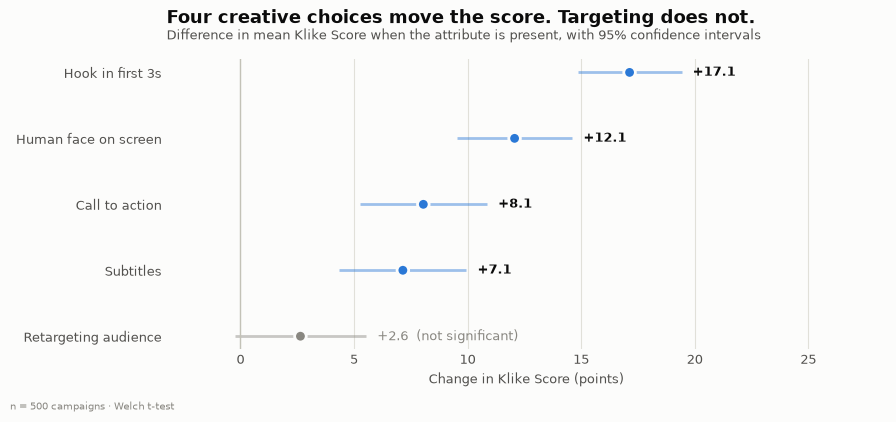

In [34]:
# CHART 1 - emphasis: which levers move the score, and which do not.
effects = binary_effects(df, "klike_score").sort_values("delta")
figure, ax = new_chart()

significant = effects["p_value"] < 0.05
colours = [BLUE if s else MUTED for s in significant]
positions = np.arange(len(effects))

ax.hlines(positions, effects["ci_low"], effects["ci_high"], color=colours, linewidth=2, alpha=0.45)
ax.scatter(effects["delta"], positions, s=70, color=colours, zorder=3, edgecolors=SURFACE, linewidths=2)
ax.axvline(0, color=BASELINE, linewidth=1)
ax.xaxis.grid(True, color=GRID, linewidth=0.8)

ax.set_yticks(positions, [LABELS[a] for a in effects["attribute"]])
ax.set_xlabel("Change in Klike Score (points)", color=INK_SOFT, fontsize=9.5)
for position, row in zip(positions, effects.itertuples()):
    label = f"{row.delta:+.1f}" + ("" if row.p_value < 0.05 else "  (not significant)")
    ax.annotate(label, xy=(row.ci_high, position), xytext=(8, 0), textcoords="offset points",
                va="center", color=INK if row.p_value < 0.05 else MUTED, fontsize=9,
                fontweight="bold" if row.p_value < 0.05 else "normal")
ax.set_xlim(effects["ci_low"].min() - 3, effects["ci_high"].max() + 9)

finish(figure, ax,
       "Four creative choices move the score. Targeting does not.",
       "Difference in mean Klike Score when the attribute is present, with 95% confidence intervals",
       "n = 500 campaigns · Welch t-test",
       name="01_creative_levers")

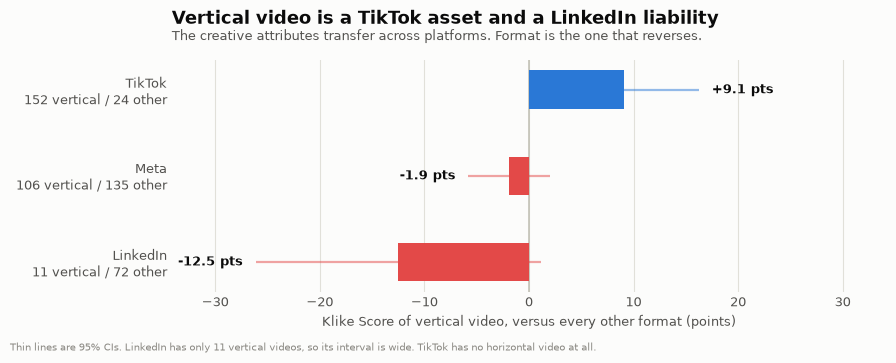

In [35]:
# CHART 2 - polarity: the one creative choice that reverses across platforms.
ORDER = ["TikTok", "Meta", "LinkedIn"]
effects = format_effect.reindex([p for p in ORDER if p in format_effect.index])

figure, ax = new_chart((9, 3.6))
positions = np.arange(len(effects))[::-1]

for position, (platform, row) in zip(positions, effects.iterrows()):
    delta = row["delta"]
    colour = BLUE if delta > 0 else RED
    ax.barh(position, delta, height=0.45, color=colour, zorder=3)
    ax.hlines(position, row["ci_low"], row["ci_high"], color=colour, linewidth=1.6, alpha=0.5, zorder=4)
    edge = row["ci_high"] if delta > 0 else row["ci_low"]
    ax.annotate(f"{delta:+.1f} pts", xy=(edge, position), xytext=(9 if delta > 0 else -9, 0),
                textcoords="offset points", va="center", ha="left" if delta > 0 else "right",
                color=INK, fontsize=9.5, fontweight="bold")

ax.axvline(0, color=BASELINE, linewidth=1.2)
ax.xaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_yticks(positions, [f"{p}\n{int(r['n_vertical'])} vertical / {int(r['n_other'])} other"
                          for p, r in effects.iterrows()])
ax.set_xlabel("Klike Score of vertical video, versus every other format (points)", color=INK_SOFT, fontsize=9.5)
span = max(abs(effects["ci_low"].min()), abs(effects["ci_high"].max())) + 8
ax.set_xlim(-span, span)

finish(figure, ax,
       "Vertical video is a TikTok asset and a LinkedIn liability",
       "The creative attributes transfer across platforms. Format is the one that reverses.",
       "Thin lines are 95% CIs. LinkedIn has only 11 vertical videos, so its interval is wide. TikTok has no horizontal video at all.",
       name="01_format_by_platform")

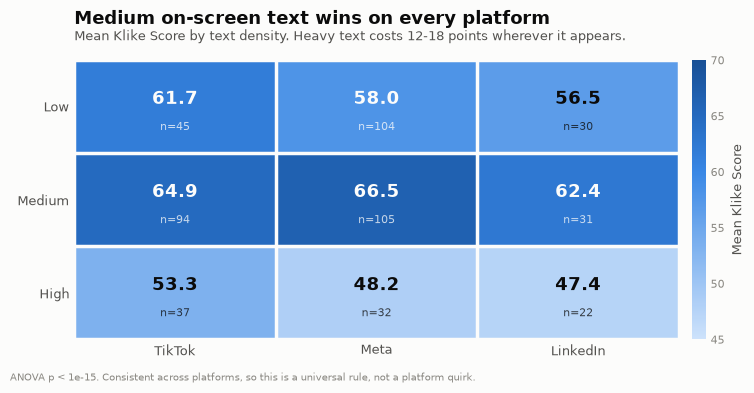

In [36]:
# CHART 3 - magnitude on a grid: one hue, light to dark, every cell labelled.
from matplotlib.colors import LinearSegmentedColormap

rows_order, platforms = ["low", "medium", "high"], ORDER
means = df.pivot_table(index="text_density", columns="platform", values="klike_score",
                       aggfunc="mean", observed=True).reindex(index=rows_order, columns=platforms)
counts = df.pivot_table(index="text_density", columns="platform", values="klike_score",
                        aggfunc="size", observed=True).reindex(index=rows_order, columns=platforms)

figure, ax = new_chart((7.6, 3.9))
image = ax.imshow(means.to_numpy(), cmap=LinearSegmentedColormap.from_list("blue", SEQUENTIAL),
                  aspect="auto", vmin=45, vmax=70)
ax.set_xticks(range(len(platforms)), platforms)
ax.set_yticks(range(len(rows_order)), [r.capitalize() for r in rows_order])
# A 2px surface gap between cells, rather than borders around them.
ax.set_xticks(np.arange(-0.5, len(platforms), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(rows_order), 1), minor=True)
ax.grid(which="minor", color=SURFACE, linewidth=2.5)
ax.tick_params(which="minor", length=0)

for r in range(len(rows_order)):
    for c in range(len(platforms)):
        value = means.iat[r, c]
        tone = SURFACE if value > 57.5 else INK
        ax.text(c, r - 0.08, f"{value:.1f}", ha="center", va="center", color=tone, fontsize=13, fontweight="bold")
        ax.text(c, r + 0.22, f"n={int(counts.iat[r, c])}", ha="center", va="center", color=tone, fontsize=8, alpha=0.75)

bar = figure.colorbar(image, ax=ax, pad=0.02, fraction=0.04)
bar.outline.set_visible(False)
bar.ax.tick_params(colors=MUTED, length=0, labelsize=8)
bar.set_label("Mean Klike Score", color=INK_SOFT, fontsize=9)

finish(figure, ax,
       "Medium on-screen text wins on every platform",
       "Mean Klike Score by text density. Heavy text costs 12-18 points wherever it appears.",
       "ANOVA p < 1e-15. Consistent across platforms, so this is a universal rule, not a platform quirk.",
       name="01_text_density")

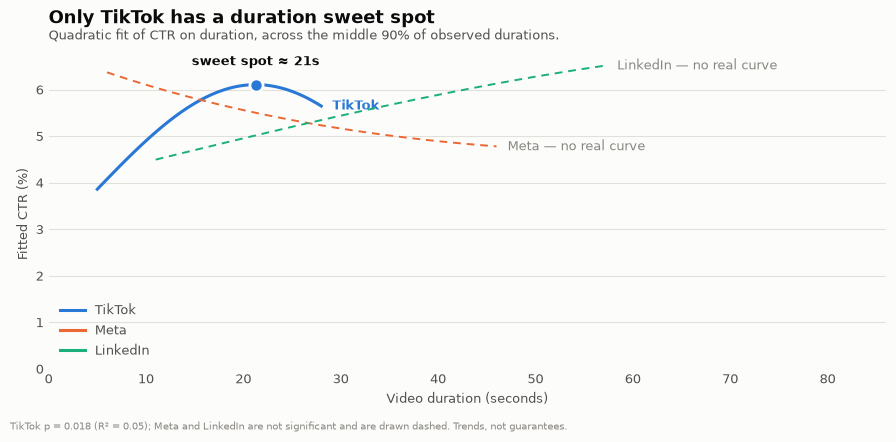

In [37]:
# CHART 4 - identity: three platforms, three series, each directly labelled.
fits = duration_response(df, "ctr")
figure, ax = new_chart((9, 4.4))

for colour, platform in zip([BLUE, ORANGE, AQUA], ORDER):
    data = df[df["platform"] == platform][["video_duration_s", "ctr"]].dropna()
    data = data[data["ctr"] > 0]
    x, y = data["video_duration_s"].to_numpy(), np.log(data["ctr"].to_numpy())
    beta, *_ = np.linalg.lstsq(np.column_stack([np.ones_like(x), x, x**2]), y, rcond=None)

    # Draw only across the middle 90% of observed durations: a quadratic
    # extrapolated into a thin tail invents a collapse the data cannot support.
    low, high = np.percentile(x, [5, 95])
    grid = np.linspace(low, high, 120)
    curve = np.exp(beta[0] + beta[1] * grid + beta[2] * grid**2) * 100

    real = fits.loc[platform, "p_value"] < 0.05
    ax.plot(grid, curve, color=colour, linewidth=2.2 if real else 1.4,
            linestyle="-" if real else (0, (4, 3)), zorder=3)
    ax.annotate(platform if real else f"{platform} — no real curve", xy=(grid[-1], curve[-1]),
                xytext=(8, 0), textcoords="offset points", color=colour if real else MUTED,
                fontsize=9.5, fontweight="bold" if real else "normal", va="center")

    peak = fits.loc[platform, "peak_seconds"]
    if real and not pd.isna(peak):
        height = np.exp(beta[0] + beta[1] * peak + beta[2] * peak**2) * 100
        ax.scatter([peak], [height], s=90, color=colour, zorder=5, edgecolors=SURFACE, linewidths=2)
        ax.annotate(f"sweet spot ≈ {peak:.0f}s", xy=(peak, height), xytext=(0, 14),
                    textcoords="offset points", ha="center", color=INK, fontsize=9.5, fontweight="bold")

ax.yaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_xlabel("Video duration (seconds)", color=INK_SOFT, fontsize=9.5)
ax.set_ylabel("Fitted CTR (%)", color=INK_SOFT, fontsize=9.5)
ax.set_xlim(0, 86)
ax.set_ylim(bottom=0)
ax.legend(handles=[plt.Line2D([], [], color=c, linewidth=2.2, label=p) for c, p in zip([BLUE, ORANGE, AQUA], ORDER)],
          frameon=False, loc="lower left", fontsize=9, labelcolor=INK_SOFT)

finish(figure, ax,
       "Only TikTok has a duration sweet spot",
       "Quadratic fit of CTR on duration, across the middle 90% of observed durations.",
       "TikTok p = 0.018 (R² = 0.05); Meta and LinkedIn are not significant and are drawn dashed. Trends, not guarantees.",
       name="01_duration_ctr")

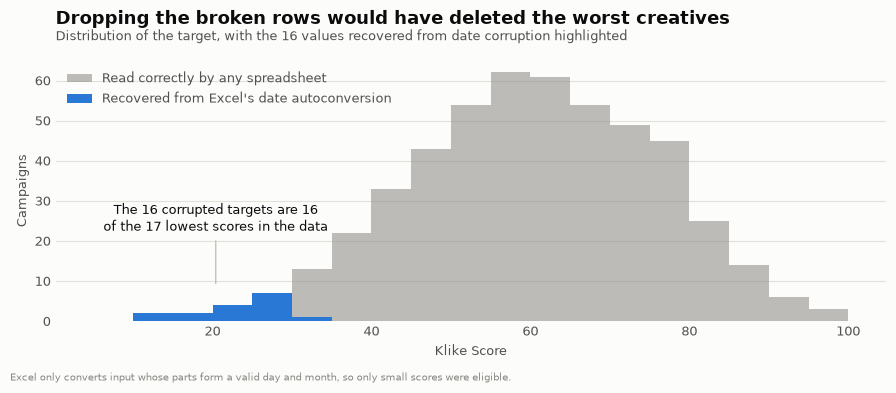

In [38]:
# CHART 5 - the data quality story, in one picture.
figure, ax = new_chart((9, 3.9))
bins = np.arange(5, 105, 5)

ax.hist(df.loc[~target_recovered, "klike_score"], bins=bins, color=MUTED, alpha=0.55,
        label="Read correctly by any spreadsheet", zorder=2)
ax.hist(df.loc[target_recovered, "klike_score"], bins=bins, color=BLUE,
        label="Recovered from Excel's date autoconversion", zorder=3)

ax.yaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_xlabel("Klike Score", color=INK_SOFT, fontsize=9.5)
ax.set_ylabel("Campaigns", color=INK_SOFT, fontsize=9.5)
ax.legend(frameon=False, fontsize=9, loc="upper left", labelcolor=INK_SOFT)

recovered_scores = df.loc[target_recovered, "klike_score"]
ax.annotate("The 16 corrupted targets are 16\nof the 17 lowest scores in the data",
            xy=((recovered_scores.min() + recovered_scores.max()) / 2, 8),
            xytext=(0, 42), textcoords="offset points", ha="center", color=INK, fontsize=9.5,
            arrowprops=dict(arrowstyle="-", color=BASELINE, linewidth=1, shrinkB=4))

finish(figure, ax,
       "Dropping the broken rows would have deleted the worst creatives",
       "Distribution of the target, with the 16 values recovered from date corruption highlighted",
       "Excel only converts input whose parts form a valid day and month, so only small scores were eligible.",
       name="01_recovered_targets")

---

# 5. Summary of Part 1

## What was wrong, and what was done

| Problem | Found | Treatment |
|---|---|---|
| Numbers stored as dates by Excel | 558 cells across 6 columns | Decoded via each cell's own display format — exact, lossless |
| Rates in mixed units | 3 conventions inside `ctr` | All rates recomputed from the counts |
| Corrupt `impressions` | 4 rows | Rebuilt from `clicks` and reported CTR |
| Corrupt `spend` | 2 rows | Rebuilt from `cpc`; confirmed by the untouched ROAS identity |
| Missing values | 7 columns, 5-9% each | Left as NaN (no leakage); indicator columns added |
| Outliers | log-normal columns | Flagged in log space, never dropped |
| Zero revenue | 72 campaigns | Marked `revenue_tracked = False`, excluded from ROAS |

**500 rows in, 500 rows out.** The headline decision was refusing to drop the 16
unparseable targets, which turned out to be 16 of the 17 worst creatives in the dataset.

## What the data says

1. **A hook in the first 3 seconds is the single biggest creative lever** — +17.1 score
   points and +68% CTR. It wins on four metrics of five; ROAS is the exception.
2. **Text density is non-monotonic**: medium beats both low and high, everywhere.
3. **The Klike Score measures the creative, not the audience.** Retargeting lifts
   conversions 237% and CTR 71% while leaving the score flat — so score-based
   recommendations must stay creative, and must not take credit for targeting's results.
4. **Creative levers transfer across platforms; format does not.** Vertical is +9.1 on
   TikTok and -12.5 on LinkedIn.
5. **Duration has no effect on the score**, a modest TikTok-only effect on CTR peaking
   near 21 seconds, and a significant negative correlation with ROAS (-0.17) everywhere.
6. **None of the four creative levers move ROAS** — only targeting (+67%) and shorter
   video do. ROAS is driven by pricing and offer, which this dataset does not carry, so
   creative advice should be judged on score, CTR, conversions and engagement.

## Open questions carried into Part 2

- `engagement_rate` has no identity to validate its scale; basis points is an assumption.
- LinkedIn is thin (83 campaigns, 11 of them vertical) — platform-specific claims there
  are directional.
- `completion_rate` predicts the score well but is an outcome, not a creative choice, so
  it cannot become a recommendation.

The clean dataset is saved at `data/klike_clean.csv` and is what Part 2 will model.